# Task 1b: Data pipeline (preprocessing and augmentation)

**Owner:** Muhammad Talha Khan (Person 2)

This notebook documents how the data goes into YOLOv8 training and why we made each choice:

1. **Data setup**: prepare the team's cleaned train/val/test split for YOLO and write `data.yaml`
2. **Image size**: experiment 416 vs 640 and the decision
3. **Augmentation**: which augmentations we use, which we switch off, and why, with example images
4. **Hand-over**: the final settings used for training (Task 2)

The cleaning and the train/val/test split were done by Person 1 (Task 1a, `notebooks/01_dataset_analysis/`).
The code used here lives in `src/data/`.

**Lecture references** (Prof. Seuß): Object Detection slides 17-19, 22 and 24; Recap 1 slides 198-210.

## How to run

Run on Kaggle:
1. Turn **Internet on** and choose a **GPU (T4)** (only needed if you re-run the image size experiment).
2. Add the dataset **garbage-split** (Add Input, Datasets).
3. Run all cells. The image size experiment is **not** re-run by default (it takes about 25 minutes); its measured results are shown instead. Set `RUN_EXPERIMENT = True` to re-run it.

In [1]:
# Paths and settings used in this notebook
REPO_URL = "https://github.com/MTalhaKhan326/cv-portfolio1.git"
REPO_DIR = "/tmp/repo"
SRC_SPLIT = "/kaggle/input/datasets/talha972/garbage-split/GarbageSplit"   # Person 1's cleaned split (read-only)
DATA_DIR = "/kaggle/working/GarbageSplit"                                  # writable copy used for training
DATA_YAML = f"{DATA_DIR}/data.yaml"

RUN_EXPERIMENT = False   # True = re-run the 416 vs 640 experiment (about 25 min on a T4)

In [2]:
# Get the latest code from GitHub. Kaggle already has numpy, pandas, OpenCV, matplotlib and
# scikit-learn, so only ultralytics is installed (installing the full requirements.txt
# would also install jupyter, which can hang the Kaggle kernel).
!rm -rf {REPO_DIR}
!git clone --depth 1 {REPO_URL} {REPO_DIR}
!pip install -q ultralytics

Cloning into '/tmp/repo'...
remote: Enumerating objects: 103, done.
remote: Counting objects: 100% (103/103), done.
remote: Compressing objects: 100% (88/88), done.
remote: Total 103 (delta 6), reused 96 (delta 5), pack-reused 0 (from 0)
Receiving objects: 100% (103/103), 49.40 MiB | 15.01 MiB/s, done.
Resolving deltas: 100% (6/6), done.


## 1. Data setup

**Input:** Person 1's cleaned and split dataset (9,405 images, 36,879 boxes, split about 71 / 14 / 14,
stratified, near-duplicates kept in the same split, seed 42).

**What `src/data/setup_data.py` does:**
- copies the split from Kaggle's read-only input folder to `/kaggle/working`, where YOLO can also write its label cache
- writes `data.yaml` with the full path, the three splits and the six class names, in the same format as the
  `coco128.yaml` example from the lecture's YOLO exercise (Object Detection, slide 24, step 6)
- checks every split: number of images and boxes, the most boxes in one image, and the share of small and large boxes

In [3]:
!python {REPO_DIR}/src/data/setup_data.py --src {SRC_SPLIT} --dst {DATA_DIR}

[copy] files to copy: 0
[copy] done -> /kaggle/working/GarbageSplit

[yaml] /kaggle/working/GarbageSplit/data.yaml
path: /kaggle/working/GarbageSplit
train: images/train
val: images/val
test: images/test

names:
  0: biodegradable
  1: cardboard
  2: glass
  3: metal
  4: paper
  5: plastic


split   images   boxes  max/img  small<1%  large>50%
train     6717   25721      229     21.9%      11.3%
val       1344    5588      234     22.8%      10.1%
test      1344    5570       84     19.0%       9.7%


**What the check shows** (measured on 10 Nov 2026):

| split | images | boxes | max boxes/img | small (<1% of image) | large (>50%) |
|---|---|---|---|---|---|
| train | 6,717 | 25,721 | 229 | 21.9% | 11.3% |
| val | 1,344 | 5,588 | 234 | 22.8% | 10.1% |
| test | 1,344 | 5,570 | 84 | 19.0% | 9.7% |

- All 36,879 boxes from Person 1's split arrive, and every image has its label file.
- About **22% of the boxes are small** (under 1% of the image area). Before cleaning it was 36%; most of the
  removed crowded biodegradable piles consisted of tiny objects.
- The most crowded image has 234 boxes. YOLO keeps up to 300 detections per image by default, so the default is enough.
- The test set has no very crowded images (max 84 boxes). This makes the test slightly easier than a real sorting belt.

## 2. Image size

YOLO resizes every image to one fixed size before training. The size decides how many pixels an object has
inside the network: the lecture's YOLO grids are 80x80, 40x40 and 20x20 at 640 input (Object Detection, slide 22),
and SPPF / PANet are meant to help small objects (slides 17-19). The lecture's code uses `imgsz=640`.

**Question:** does enlarging our images to 640 help, given that 22% of the objects are small?

**Experiment** (`src/data/image_size_experiment.py`): YOLOv8n, pretrained, 10 epochs, same split, same seed (42),
same augmentation; only the image size differs. Scores on the **validation** set (the test set stays untouched).

In [4]:
import pandas as pd

if RUN_EXPERIMENT:
    !python {REPO_DIR}/src/data/image_size_experiment.py --data {DATA_YAML}
else:
    # Measured on the cleaned split, 10 Nov 2026 (Kaggle, Tesla T4)
    overall = pd.DataFrame(
        {"mAP@0.5": [0.563, 0.540], "mAP@0.5:0.95": [0.393, 0.374],
         "train time (10 epochs)": ["6.1 min", "9.2 min"], "GPU memory": ["2.1 GB", "4.9 GB"]},
        index=pd.Index([416, 640], name="imgsz"))
    per_class = pd.DataFrame(
        {"416": [0.404, 0.533, 0.647, 0.689, 0.567, 0.536],
         "640": [0.388, 0.530, 0.626, 0.676, 0.520, 0.505]},
        index=pd.Index(["biodegradable", "cardboard", "glass", "metal", "paper", "plastic"], name="mAP@0.5 per class"))
    display(overall)
    display(per_class)

,mAP@0.5,mAP@0.5:0.95,train time (10 epochs),GPU memory
imgsz,,,,
416,0.563,0.393,6.1 min,2.1 GB
640,0.540,0.374,9.2 min,4.9 GB


,416,640
mAP@0.5 per class,,
biodegradable,0.404,0.388
cardboard,0.533,0.530
glass,0.647,0.626
metal,0.689,0.676
paper,0.567,0.520
plastic,0.536,0.505


**Decision: `imgsz=416`**

- 416 scored higher overall (mAP@0.5 0.563 vs 0.540) and for **all six classes**.
- 416 trained about 1.5x faster and needed less than half the GPU memory.
- Our images are 416x416. Enlarging them to 640 adds no new detail, it only interpolates (blurs) the pixels.
- The same result came out on the original, uncleaned data (0.566 vs 0.546), and Task 2's full 100-epoch
  YOLOv8s training also found 416 and 640 practically equal.

**Limitations:** only 10 epochs and one seed per size; larger images learn more slowly, so the gap could shrink
with longer training (Recap 1, slide 202: training is stochastic, repeat runs give more reliable comparisons).

**Side finding:** biodegradable is the weakest class (mAP@0.5 0.40, recall 0.32), likely because of small objects in piles.

## 3. Augmentation

**Why:** augmentation creates new variations of the training images on the fly, so the model learns the objects
instead of memorising the photos. It is the lecture's first answer to overfitting (Recap 1, slides 205-209).
The rule we follow (Recap 1, slide 210): a transformation is only allowed if the object **keeps its class**.

**How it works during training:** YOLO takes batches of 16 images. For each image it applies, in this order:
mosaic, zoom and shift (scale, translate), colour change (HSV), horizontal flip. Every step is random, so the same
photo looks different in every epoch. The boxes are moved with the image. Nothing is saved to disk.
**Validation and test images are never augmented**, only resized.

| Augmentation | Setting | Decision | Reason |
|---|---|---|---|
| Horizontal flip | `fliplr=0.5` | on | A mirrored bottle or can keeps its class |
| Vertical flip | `flipud=0.0` | off | The dataset already contains some upside-down images; more would make that view too common |
| Hue (colour tone) | `hsv_h=0.015` | small | Colour helps identify the material (green glass, brown cardboard); a strong shift could create materials that do not exist |
| Saturation, brightness | `hsv_s=0.7`, `hsv_v=0.4` | on | Web images with very different lighting |
| Mosaic (4 images in 1) | `mosaic=1.0` | on | Creates multi-object scenes and objects at different scales |
| Zoom, shift | `scale=0.5`, `translate=0.1` | on | Objects appear at different sizes and positions |
| Rotation | `degrees=0.0` | off | Rotating makes axis-aligned boxes larger and less accurate |
| MixUp | `mixup=0.0` | off | Blending two images creates see-through mixtures of materials (e.g. glass and plastic) |

These are YOLO's default values; the point is that each one was checked against our data.

**Important:** YOLO switches mosaic off for the last 10 epochs (`close_mosaic=10`), so the final training must run
clearly longer than 10 epochs.

The figure below recreates the augmentations on real training images (a simplified mosaic with four equal tiles),
plus one augmentation we deliberately do **not** use.

Saved: /kaggle/working/augmentation_examples.png
Main image: glass269_jpg.rf.50d4982daffa34208ee97ee9815c791d.jpg
Mosaic images: ['biodegradable1087_jpg.rf.9161d4627bf7927f36d9ffcfd120a63a.jpg', 'cardboard575_jpg.rf.dd4f3707dc0169e459328b9f8761ae64.jpg', 'metal209_jpg.rf.b1f6b41e06aae8b92b77e844ceae30fe.jpg', 'plastic603_jpg.rf.a723974ac32453b886c8d69e8762922a.jpg']


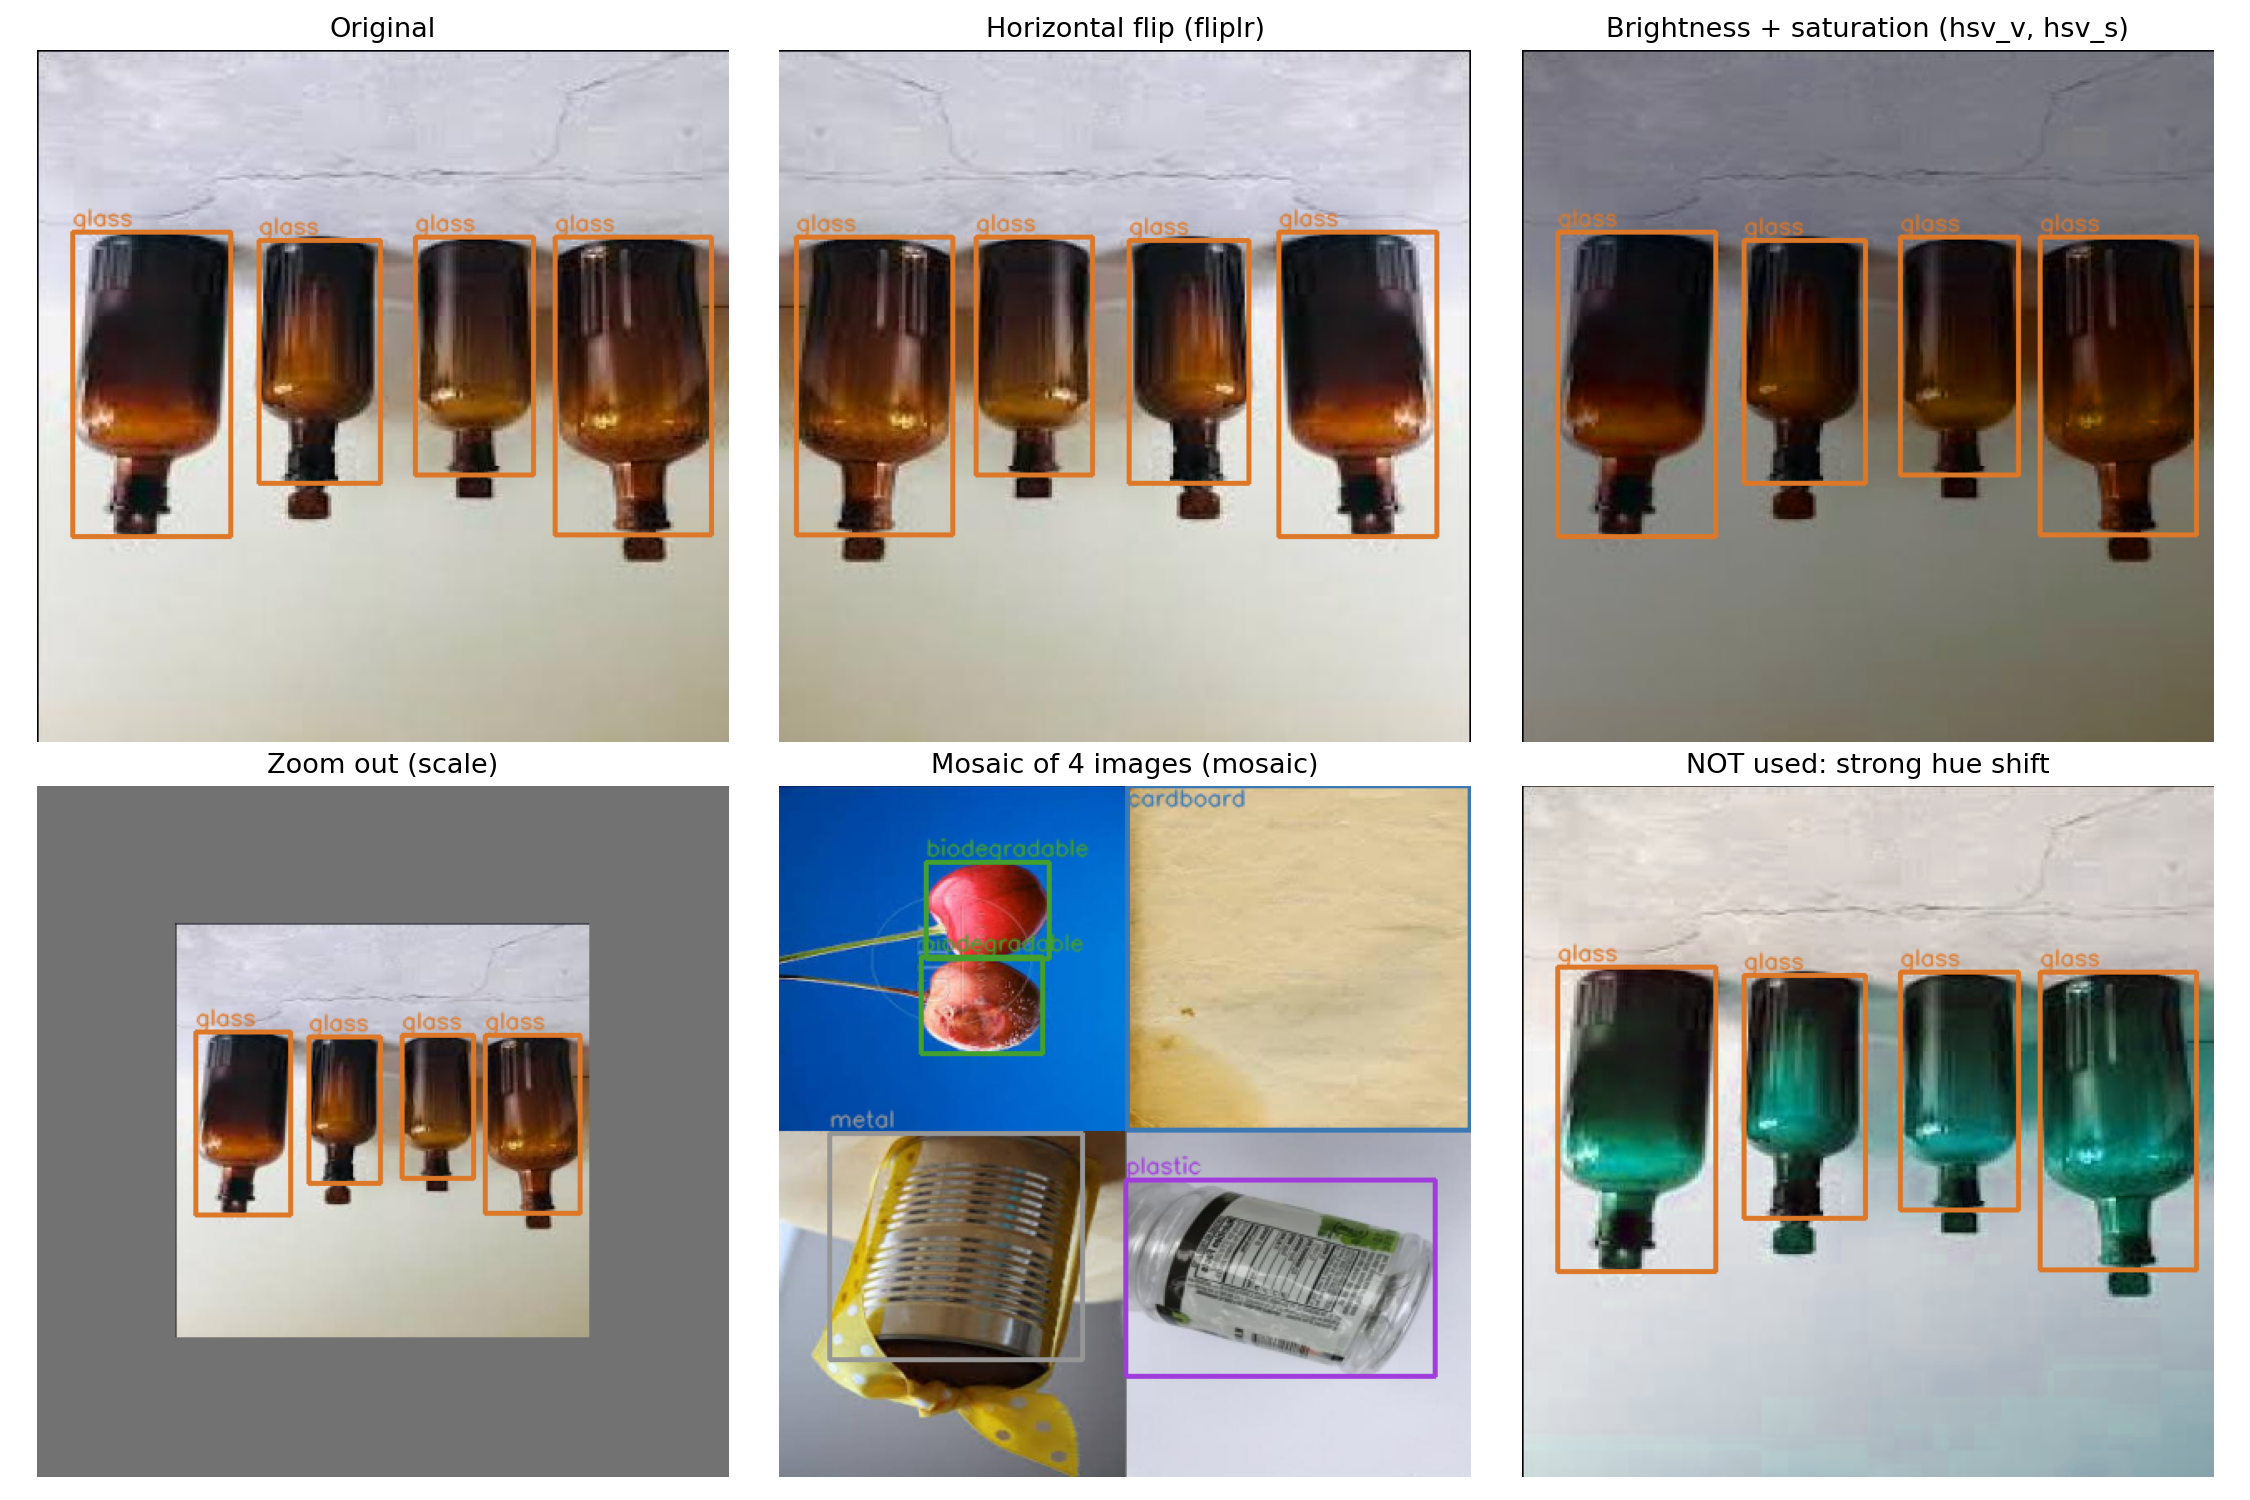

In [5]:
from IPython.display import Image, display

!python {REPO_DIR}/src/data/show_augmentations.py --data-dir {DATA_DIR} --out /kaggle/working/augmentation_examples.png
display(Image("/kaggle/working/augmentation_examples.png"))

**What the figure shows:** the boxes move with the image in every panel, so the labels stay correct.
The last panel shows why the hue change stays small: green glass turns blue or purple, which looks like a different material.

## 4. Hand-over to Task 2 (training)

These are the data settings for the final training. Task 2 adds its own model and optimisation settings
(model size, epochs, batch size, learning rate, early stopping).

In [6]:
DATA_SETTINGS = dict(
    data=DATA_YAML,
    imgsz=416,
    fliplr=0.5, flipud=0.0,
    hsv_h=0.015, hsv_s=0.7, hsv_v=0.4,
    scale=0.5, translate=0.1, degrees=0.0,
    mosaic=1.0, mixup=0.0,
    seed=42,
)
for key, value in DATA_SETTINGS.items():
    print(f"{key:<10} {value}")

# Usage in Task 2:
# from ultralytics import YOLO
# YOLO("yolov8s.pt").train(**DATA_SETTINGS, epochs=..., batch=..., patience=...)

data       /kaggle/working/GarbageSplit/data.yaml
imgsz      416
fliplr     0.5
flipud     0.0
hsv_h      0.015
hsv_s      0.7
hsv_v      0.4
scale      0.5
translate  0.1
degrees    0.0
mosaic     1.0
mixup      0.0
seed       42


## Summary

- **Data:** Person 1's cleaned split, prepared for YOLO on Kaggle with one `data.yaml` (coco128 format).
- **Image size:** 416, tested against the lecture's default 640 and better for every class, faster and lighter.
- **Augmentation:** horizontal flip, mild colour changes, mosaic, zoom and shift on; vertical flip, rotation,
  strong hue shift and MixUp off, each for a reason tied to our data.
- **Open points for the team:** biodegradable is the weakest class; the test set contains no very crowded images.